
# Comprehensive Assignment on Numerical Solution to ODEs
## Implementing the Leapfrog Method to Solve an Initial Value Problem

### Objective

The objective of this assignment is to implement the Leapfrog numerical method to solve an initial value problem (IVP). The method is applied to the electron plasma oscillation problem. The numerical solution is compared with the exact analytical solution to study accuracy, convergence and stability.

The Leapfrog method is widely used in Particle-in-Cell (PIC) simulations to advance particle positions and velocities under electric and magnetic fields.

All quantities are considered in normalized units, so no physical constants are required.




## 1. Governing Equations

For a one-dimensional electron plasma oscillation, the governing differential equations are:

$$
\frac{dx}{dt}=v,\qquad
\frac{dv}{dt}=-\omega_p^2x
$$

where,

- $x$ represents the particle position.
- $v$ represents the particle velocity.
- $\omega_p$ represents the plasma frequency.

The initial conditions are:

$$
x(0)=0.5,\qquad v(0)=0
$$

The plasma frequency and time domain are:

$$
\omega_p=1,\qquad 0\leq t\leq20
$$

### Exact Analytical Solution

The exact analytical solutions are:

$$
x(t)=0.5\cos(\omega_pt)
$$

$$
v(t)=-0.5\omega_p\sin(\omega_pt)
$$



## 2. Leapfrog Numerical Method

The Leapfrog method is an explicit numerical integration technique in which position and velocity are evaluated at staggered time levels.

Position is calculated at integer time levels:

$$
t_n=nh
$$

Velocity is calculated at half time levels:

$$
t_{n+1/2}=\left(n+\frac12\right)h
$$

where $h$ is the time-step size.

The numerical update equations are:

### Kick Step

$$
v_{n+1/2}=v_{n-1/2}-h\omega_p^2x_n
$$

### Drift Step

$$
x_{n+1}=x_n+hv_{n+1/2}
$$

Since the initial velocity is given at $t=0$, the initial half-step velocity is calculated using:

$$
v_{-1/2}=v_0-\frac{h}{2}a(x_0)
$$

where,

$$
a(x)=-\omega_p^2x
$$

Therefore,

$$
\boxed{v_{-1/2}=v_0+\frac{h}{2}\omega_p^2x_0}
$$


In [1]:

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

plt.rcParams['figure.figsize'] = (8, 5)
plt.rcParams['font.size'] = 11



## 3. Mathematical Formulation and Discretization

The governing equation for electron plasma oscillation is:

$$
\frac{dv}{dt}=-\omega_p^2x
$$

Using the central difference approximation at the integer time level:

$$
\left.\frac{dv}{dt}\right|_n
\approx
\frac{v_{n+1/2}-v_{n-1/2}}{h}
$$

Substituting the governing equation:

$$
\frac{v_{n+1/2}-v_{n-1/2}}{h}
=-\omega_p^2x_n
$$

Rearranging:

$$
v_{n+1/2}=v_{n-1/2}-h\omega_p^2x_n
$$

Similarly, the position update equation is:

$$
\frac{x_{n+1}-x_n}{h}=v_{n+1/2}
$$

Therefore,

$$
x_{n+1}=x_n+hv_{n+1/2}
$$

These two equations form the Leapfrog integration scheme.


In [2]:

def leapfrog(x, v, h, wp=1.0):

    # Kick step: update velocity
    v_new = v - h * wp**2 * x

    # Drift step: update position
    x_new = x + h * v_new

    return x_new, v_new



## 4. Numerical Implementation

The Leapfrog method is implemented using Python. The initial conditions are:

$$
x_0=0.5,\qquad v_0=0
$$

The time-step size is selected as:

$$
h=0.1
$$

The total simulation time is:

$$
t_{\text{end}}=20
$$

The initial velocity is shifted backward by half a time step to obtain the staggered initial velocity.

The numerical solution is then calculated iteratively using the Leapfrog method.


In [3]:

# Parameters
h = 0.1
t_end = 20.0
wp = 1.0

x0 = 0.5
v0 = 0.0

# Number of time steps
n = int(t_end / h)

# Time arrays
t_x = np.linspace(0, t_end, n + 1)
t_v = t_x[:-1] + 0.5 * h

# Initial half-step velocity
a0 = -(wp**2) * x0
v = v0 - 0.5 * h * a0
x = x0

# Arrays for numerical solutions
x_num = np.zeros(n + 1)
v_num = np.zeros(n)

x_num[0] = x

# Leapfrog integration
for i in range(n):

    x, v = leapfrog(x, v, h, wp)

    x_num[i + 1] = x
    v_num[i] = v

# Exact analytical solutions
x_exact = x0 * np.cos(wp * t_x)
v_exact = -x0 * wp * np.sin(wp * t_v)

print("Number of time steps:", n)

print("Maximum position error:",
      np.max(np.abs(x_num - x_exact)))

print("Maximum velocity error:",
      np.max(np.abs(v_num - v_exact)))


Number of time steps: 200
Maximum position error: 0.0038152808690173623
Maximum velocity error: 0.00393146012390859



## 5. Comparison of Numerical and Analytical Solutions

The numerical results obtained using the Leapfrog method are compared with the exact analytical solutions.

The following plots are generated:

1. Position versus time.
2. Velocity versus time.
3. Phase-space trajectory (position versus velocity).

The comparison helps evaluate the accuracy of the numerical integration method.

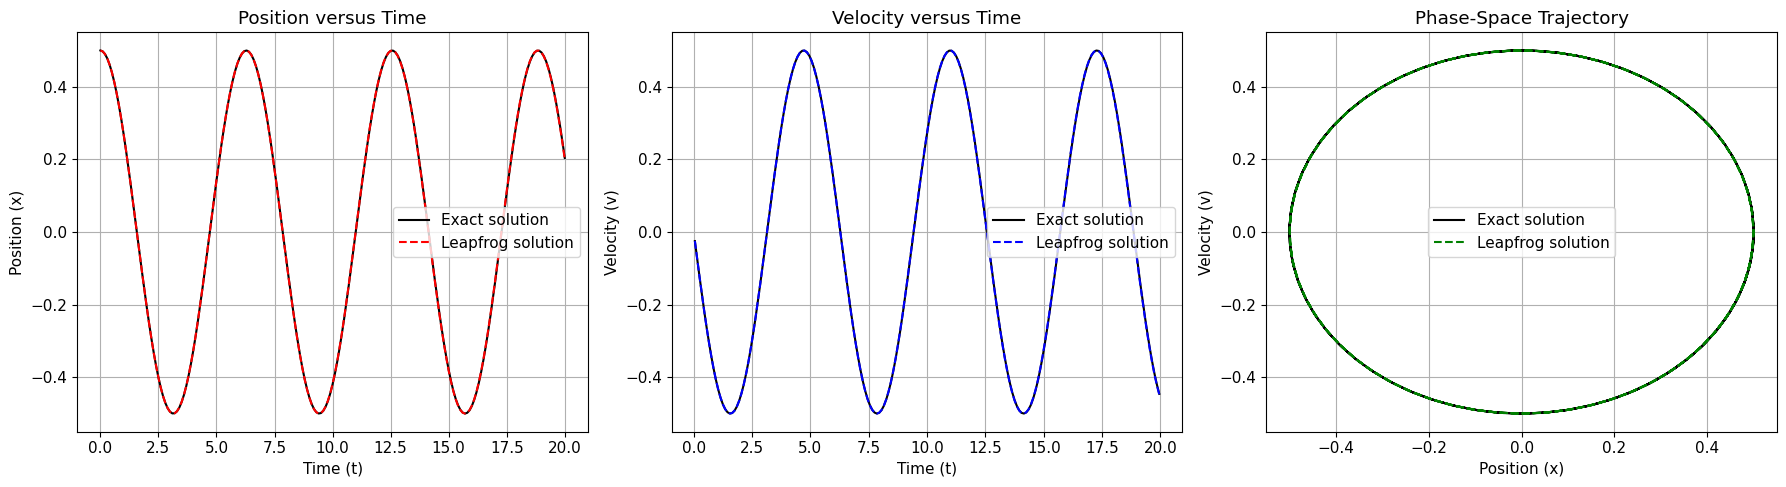

In [4]:

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Position versus time
axes[0].plot(t_x, x_exact, 'k-', label='Exact solution')
axes[0].plot(t_x, x_num, 'r--', label='Leapfrog solution')

axes[0].set_xlabel('Time (t)')
axes[0].set_ylabel('Position (x)')
axes[0].set_title('Position versus Time')
axes[0].legend()
axes[0].grid()

# Velocity versus time
axes[1].plot(t_v, v_exact, 'k-', label='Exact solution')
axes[1].plot(t_v, v_num, 'b--', label='Leapfrog solution')

axes[1].set_xlabel('Time (t)')
axes[1].set_ylabel('Velocity (v)')
axes[1].set_title('Velocity versus Time')
axes[1].legend()
axes[1].grid()

# Phase-space trajectory
t_mid = t_v

x_mid = 0.5 * (x_num[:-1] + x_num[1:])

x_phase_exact = x0 * np.cos(wp * t_mid)
v_phase_exact = -x0 * wp * np.sin(wp * t_mid)

axes[2].plot(x_phase_exact, v_phase_exact,
             'k-', label='Exact solution')

axes[2].plot(x_mid, v_num,
             'g--', label='Leapfrog solution')

axes[2].set_xlabel('Position (x)')
axes[2].set_ylabel('Velocity (v)')
axes[2].set_title('Phase-Space Trajectory')
axes[2].legend()
axes[2].grid()

plt.tight_layout()
plt.show()



## 6. Convergence Analysis

The convergence of the Leapfrog method is investigated by considering different time-step sizes:

$$
h=0.2,\quad 0.1,\quad 0.05,\quad 0.025
$$

The maximum position error is calculated using:

$$
e(h)=\max_n|x_n-x(t_n)|
$$

The observed order of convergence is estimated using:

$$
p=\log_2\left(\frac{e(h)}{e(h/2)}\right)
$$

The results are compared for two different initializations:

### 1. Staggered Initialization

$$
v_{-1/2}=v_0-\frac{h}{2}a(x_0)
$$

### 2. Unstaggered Initialization

$$
v_{-1/2}=v_0
$$


In [5]:

h_values = [0.2, 0.1, 0.05, 0.025]

errors_staggered = []
errors_unstaggered = []

for step in h_values:

    n_steps = int(20 / step)
    tx = np.linspace(0, 20, n_steps + 1)

    exact = 0.5 * np.cos(tx)

    # Staggered initialization
    x = 0.5
    v = 0.5 * step

    xn = [x]

    for i in range(n_steps):
        x, v = leapfrog(x, v, step)
        xn.append(x)

    errors_staggered.append(
        np.max(np.abs(np.array(xn) - exact))
    )

    # Unstaggered initialization
    x = 0.5
    v = 0.0

    xn = [x]

    for i in range(n_steps):
        x, v = leapfrog(x, v, step)
        xn.append(x)

    errors_unstaggered.append(
        np.max(np.abs(np.array(xn) - exact))
    )

# Calculate observed orders
p_staggered = [np.nan]
p_unstaggered = [np.nan]

for i in range(1, len(h_values)):

    p_staggered.append(
        np.log2(errors_staggered[i-1] /
                errors_staggered[i])
    )

    p_unstaggered.append(
        np.log2(errors_unstaggered[i-1] /
                errors_unstaggered[i])
    )

# Create results table
results = pd.DataFrame({
    'Time Step': h_values,
    'Staggered Error': errors_staggered,
    'Staggered Order': p_staggered,
    'Unstaggered Error': errors_unstaggered,
    'Unstaggered Order': p_unstaggered
})

display(results)


,Time Step,Staggered Error,Staggered Order,Unstaggered Error,Unstaggered Order
0,0.200,0.048888,NaN,0.064557,NaN
1,0.100,0.024687,0.985742,0.028628,1.173135
2,0.050,0.012421,0.991002,0.013402,1.095029
3,0.025,0.006230,0.995438,0.006475,1.049370



### Discussion of Convergence Results

The Leapfrog method with correct staggered initialization is expected to show second-order convergence.

$$
p\approx2
$$

This is because the method uses a centered difference approximation and the initial velocity is correctly evaluated at the half time level.

For the unstaggered initialization, the initial half-step velocity is incorrectly assumed to be equal to the initial velocity at $t=0$.

This introduces an additional starting error of order $O(h)$, which reduces the overall observed convergence order.

Therefore, correct half-step initialization is important for obtaining the expected accuracy of the Leapfrog method.



## 7. Equivalence to the Central-Difference Formula

The Leapfrog drift equation is:

$$
x_{n+1}=x_n+hv_{n+1/2}
$$

Therefore,

$$
v_{n+1/2}=\frac{x_{n+1}-x_n}{h}
$$

Similarly,

$$
v_{n-1/2}=\frac{x_n-x_{n-1}}{h}
$$

The kick equation is:

$$
v_{n+1/2}=v_{n-1/2}-h\omega_p^2x_n
$$

Substituting the velocity expressions:

$$
\frac{x_{n+1}-x_n}{h}
=
\frac{x_n-x_{n-1}}{h}
-h\omega_p^2x_n
$$

Multiplying by $h$ and rearranging:

$$
\boxed{
x_{n+1}-2x_n+x_{n-1}
=-\omega_p^2h^2x_n
}
$$

This is the central-difference formula for the second-order differential equation.



## 8. Stability Analysis

The central-difference equation is:

$$
x_{n+1}-2x_n+x_{n-1}
=-\omega_p^2h^2x_n
$$

Rearranging:

$$
x_{n+1}-(2-\omega_p^2h^2)x_n+x_{n-1}=0
$$

Assume a trial solution:

$$
x_n=\lambda^n
$$

Substituting:

$$
\lambda^2-(2-\omega_p^2h^2)\lambda+1=0
$$

The characteristic roots must have magnitude equal to one for bounded oscillations.

This leads to the stability condition:

$$
-1<1-\frac{\omega_p^2h^2}{2}<1
$$

Simplifying:

$$
0<\omega_p^2h^2<4
$$

Therefore, the stability condition is:

$$
\boxed{\omega_ph<2}
$$

If $\omega_ph>2$, one of the characteristic roots has magnitude greater than one, resulting in an unstable numerical solution.

At the limiting value $\omega_ph=2$, the characteristic equation has a repeated root of $-1$. Therefore, the practical stability condition is taken as strictly less than 2.


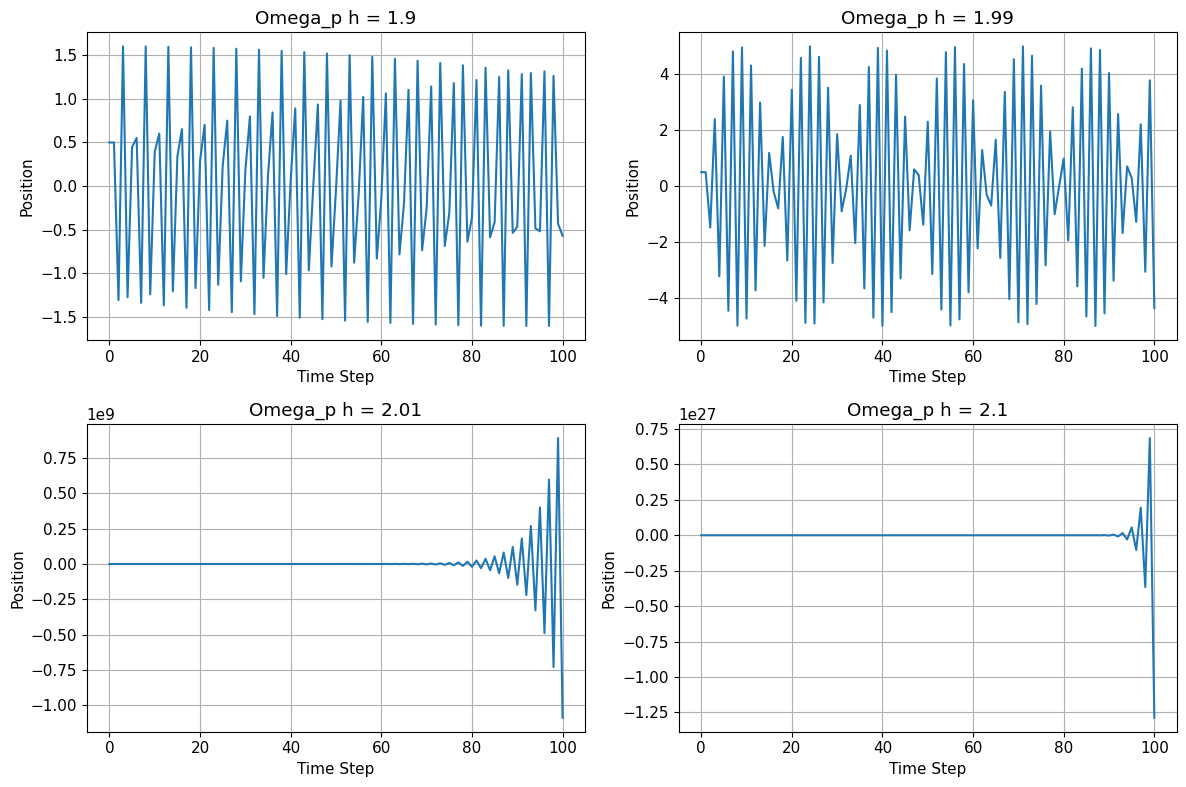

,Omega_p h,Maximum amplitude,Behaviour
0,1.90,1.601254e+00,Stable
1,1.99,5.005990e+00,Stable
2,2.01,1.087079e+09,Unstable
3,2.10,1.287730e+27,Unstable


In [6]:

wph_values = [1.9, 1.99, 2.01, 2.1]

wp = 1.0
n_steps = 100

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
axes = axes.ravel()

stability_results = []

for ax, wph in zip(axes, wph_values):

    h_test = wph / wp

    x = 0.5
    v = 0.5 * h_test * wp**2

    x_values = [x]

    for i in range(n_steps):

        x, v = leapfrog(x, v, h_test, wp)
        x_values.append(x)

    max_amplitude = np.max(np.abs(x_values))

    stability_results.append({
        'Omega_p h': wph,
        'Maximum amplitude': max_amplitude,
        'Behaviour': 'Stable' if wph < 2 else 'Unstable'
    })

    ax.plot(x_values)
    ax.set_title(f'Omega_p h = {wph}')
    ax.set_xlabel('Time Step')
    ax.set_ylabel('Position')
    ax.grid()

plt.tight_layout()
plt.show()

# Display stability results
stability_table = pd.DataFrame(stability_results)

display(stability_table)



### Discussion of Stability Results

The stability analysis is performed for the following values:

$$
\omega_ph=1.9,\quad 1.99,\quad 2.01,\quad 2.1
$$

For values below 2, the numerical solution remains bounded and oscillatory.

For values greater than 2, the numerical solution becomes unstable and its amplitude increases with time.

The stability condition is particularly important in Particle-in-Cell (PIC) simulations because the time step must be sufficiently small to resolve the plasma oscillation frequency.

Violation of this condition leads to numerical instability.

Therefore, the time-step size must satisfy:

$$
\boxed{h<\frac{2}{\omega_p}}
$$



## 9. Conclusion

In this assignment, the Leapfrog numerical integration method was implemented to solve the electron plasma oscillation problem.

The numerical solution was compared with the exact analytical solution, and position, velocity and phase-space plots were generated.

The convergence study demonstrated that the Leapfrog method with correct staggered initialization achieves approximately second-order accuracy. Incorrect initialization introduces a first-order starting error and reduces the observed convergence order.

The Leapfrog scheme was also shown to be equivalent to the central-difference formula:

$$
x_{n+1}-2x_n+x_{n-1}
=-\omega_p^2h^2x_n
$$

The stability analysis established the condition:

$$
\boxed{\omega_ph<2}
$$

The numerical verification confirmed that the solution remains bounded below the stability limit and becomes unstable when the limit is exceeded.

Thus, the Leapfrog method provides an effective numerical technique for solving oscillatory initial value problems and is particularly useful in Particle-in-Cell simulations.
